In [10]:
# 1. Import the tensorflow
import tensorflow as tf
import matplotlib.pyplot as plt

In [11]:
# 2. Load the mnist dataset
data = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = data.load_data()

In [12]:
# 3. Normalize pixel values (0-255) to 0.0 -1.0 range for stabile gradient descent
X_train, X_test = X_train / 255.0, X_test /255.0

In [13]:
# 4. Defining the model architecture
model = tf.keras.Sequential([
    # Input layer: flatten the 28x28 input images here,
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    # Hidden layer to process features and activation function relu
    tf.keras.layers.Dense(128, activation='relu'),
    # Output layer yielding probabilities for 10 digit classes
    tf.keras.layers.Dense(10, activation='softmax')
])

In [16]:
# 5. Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
# Training the model
# Also using validation_split=0.2 to monitor performance on unseen data during training
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9959 - loss: 0.0137 - val_accuracy: 0.9755 - val_loss: 0.1004
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9965 - loss: 0.0120 - val_accuracy: 0.9722 - val_loss: 0.1200
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9965 - loss: 0.0107 - val_accuracy: 0.9753 - val_loss: 0.1074
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9985 - loss: 0.0063 - val_accuracy: 0.9739 - val_loss: 0.1105
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9975 - loss: 0.0084 - val_accuracy: 0.9717 - val_loss: 0.1252
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9976 - loss: 0.0082 - val_accuracy: 0.9760 - val_loss: 0.1118
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9983 - loss: 0.0058 - val_accuracy: 0.9754 - val_loss: 0.1215
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9985 - loss: 0.0053 - 

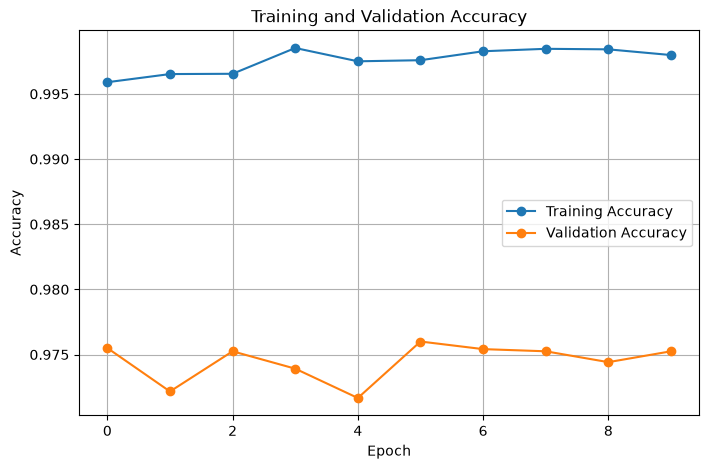

In [19]:
# 5. Plot training results
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## Result
It seems like the model was learning during the first epocs little. But the loss and validation both were fluctuating and then started increasing at the last epocs which means the model was overfitting and memorizing the data rather than learning and predecting.